# Dimension 2 · Phase 2 — Institutional layer
## Budgetary retrenchment by spending organisation, Argentina 2025 vs 2023

**Paper:** *Anti-statist sustainability backlash: Libertarian narratives and the erosion of
state capacities in Argentina under Milei* — Section 5.2.1 (Budgetary retrenchment).

**What this notebook does.** Phase 1 measured retrenchment by budget *function* (what the money
is for). This notebook measures it by *organisation* (who spends it) — the unit that decrees
restructure, and therefore the unit that connects the budgetary and administrative rows of
Table 2.

**Scope, fixed by the research team:**

| Decision | Value |
|---|---|
| Comparison | **2025 vs 2023 only** — a single deflation step, no chained years |
| Measure | `credito_devengado` (executed / accrued) |
| Base year | 2023 — the last year with a Budget Law approved by Congress |
| Universe | Administración Nacional |
| Deflator | INDEC CPI, national, general level, **annual average** |
| Secondary indicator | share of total national budget (deflator-free) |

**How to run it.** First build the master extract once — `python ../scripts/00_build_master.py`
— which downloads and parses the source files and writes `processed/master_{year}.parquet`.
Then run this notebook top to bottom; it reads those files and takes a few seconds. The CPI
series is still fetched live from INDEC's API, which needs no key.

**Dependencies:** `pandas`, `matplotlib`, and the standard library. No other packages.

---
## 1. Setup

In [1]:
import io
import json
import re
import ssl
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The master extract built by scripts/00_build_master.py. Change if you moved it.
MASTER_DIR = Path("../processed")
OUT_DIR = Path("../outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

YEARS = [2023, 2025]
BASE_YEAR = 2023

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Some Argentine government hosts present certificate chains that Python's default
# store rejects. We relax verification for these public, read-only data endpoints only.
SSL_CTX = ssl.create_default_context()
SSL_CTX.check_hostname = False
SSL_CTX.verify_mode = ssl.CERT_NONE

HEADERS = {"User-Agent": "Mozilla/5.0 (academic research; budget analysis)"}


def fetch(url: str, timeout: int = 300) -> bytes:
    """GET a URL and return the raw bytes."""
    req = urllib.request.Request(url, headers=HEADERS)
    with urllib.request.urlopen(req, context=SSL_CTX, timeout=timeout) as r:
        return r.read()

---
## 2. The datasets

### 2.1 Budget microdata — *Presupuesto de gastos y su ejecución detallada (agrupación anual)*

Published by the **Dirección General de Sistemas Informáticos de Administración Financiera
(DGSIAF)**, Secretaría de Hacienda, through the *Presupuesto Abierto* portal
(<https://www.presupuestoabierto.gob.ar/sici/datos-abiertos>), under CC-BY 4.0.

There is also a REST API (<https://presupuesto-abierto.argentina.apidocs.ar/>) which requires a
free token. **We deliberately do not use it.** The bulk annual files give the complete
row-level microdata rather than pre-aggregated query results, which is what the institutional
and programme layers need, and they require no credential — so this notebook is reproducible by
anyone without registration.

One row per unique combination of every classifier, with all five credit stages:

| Column group | Columns |
|---|---|
| Institutional | `jurisdiccion_*`, `subjurisdiccion_*`, `entidad_*`, `servicio_*` (SAF) |
| Programmatic | `programa_*`, `subprograma_*`, `proyecto_*`, `actividad_*`, `obra_*` |
| Functional | `finalidad_*`, `funcion_*` |
| Object / economic | `inciso_*`, `principal_*`, `parcial_*`, `clasificador_economico_*` |
| Other | `fuente_financiamiento_*`, `ubicacion_geografica_*`, `unidad_ejecutora_*` |
| **Measures** | `credito_presupuestado`, `credito_vigente`, `credito_comprometido`, `credito_devengado`, `credito_pagado` |

Field-by-field documentation: <https://dgsiaf-repo.mecon.gob.ar/repository/pa/credito-anual.pdf>

> **Gotcha that will silently corrupt your results.** The amounts use a **decimal comma** and no
> thousands separator (`48645,776825`). Pandas reads them as strings, and `.sum()` on a string
> column *concatenates* rather than adds — producing a nonsense number without raising an error.
> The loader below asserts there is no `.` in the raw values before converting.

Units: **millones de pesos corrientes**.

In [2]:
def credito_url(year: int) -> str:
    """Direct download URL for the annual expenditure microdata.

    These URLs come from the portal's own catalogue endpoint,
    https://www.presupuestoabierto.gob.ar/sici/rest-api/catalog/site , which returns a JSON
    listing of every dataset with its `urlArchivo`. Re-run `discover_datasets()` below if the
    pattern ever changes.
    """
    return f"https://dgsiaf-repo.mecon.gob.ar/repository/pa/datasets/{year}/credito-anual-{year}.zip"


def discover_datasets(name_contains: str = "ejecución detallada - agrupación anual"):
    """Query the Presupuesto Abierto catalogue and list matching datasets and their URLs."""
    cat = json.loads(fetch("https://www.presupuestoabierto.gob.ar/sici/rest-api/catalog/site").decode("utf8"))
    rows = [
        {"ejercicios": d["ejercicios"], "recurso": d["nombreRecurso"],
         "actualizado": d["fechaDeActualizacion"], "registros": d["cantidadDeRegistros"],
         "url": d["urlArchivo"]}
        for d in cat["distribuciones"] if name_contains.lower() in d["nombreRecurso"].lower()
    ]
    return pd.DataFrame(rows).sort_values("ejercicios", key=lambda s: s.map(lambda x: x[0]))


# Provenance check: which vintage of each file are we about to use?
catalogue = discover_datasets()
display(catalogue[catalogue.ejercicios.map(lambda e: bool(set(e) & set(YEARS)))])

,ejercicios,recurso,actualizado,registros,url
29,[2023],Presupuesto de gastos y su ejecución detallada...,30 jun 2024,131710,https://dgsiaf-repo.mecon.gob.ar/repository/pa...
30,[2025],Presupuesto de gastos y su ejecución detallada...,5 jul 2026,113218,https://dgsiaf-repo.mecon.gob.ar/repository/pa...


In [3]:
MEASURES = ["credito_presupuestado", "credito_vigente", "credito_devengado"]

USECOLS = [
    "ejercicio_presupuestario", "subsector_desc", "caracter_desc",
    "jurisdiccion_id", "jurisdiccion_desc",
    "entidad_id", "entidad_desc",
    "servicio_id", "servicio_desc",
    "programa_id", "programa_desc",
    "actividad_id", "actividad_desc",
    "finalidad_id", "funcion_id", "funcion_desc",
    "inciso_id", "inciso_desc",
] + MEASURES


def load_credito(year):
    """Read one year from the master extract built by `scripts/00_build_master.py`.

    All parsing — the decimal-comma conversion, the dtype decisions, the FARN
    validation — happens once, in that script. This notebook does not re-parse
    raw CSV, so it cannot drift from the other notebooks. If the master files are
    missing, run:

        python ../scripts/00_build_master.py

    See `../processed/master_manifest.csv` for the provenance and vintage of each
    file, and note that the publisher revises past years.
    """
    for name in (f"master_{year}.parquet", f"master_{year}.csv.gz"):
        path = MASTER_DIR / name
        if path.exists():
            df = (pd.read_parquet(path, columns=USECOLS) if path.suffix == ".parquet"
                  else pd.read_csv(path, usecols=USECOLS, low_memory=False))
            df["anio"] = year
            return df
    raise FileNotFoundError(
        f"no master file for {year} in {MASTER_DIR.resolve()} — "
        "run `python ../scripts/00_build_master.py` first"
    )

credito = {y: load_credito(y) for y in YEARS}

for y in YEARS:
    d = credito[y]
    print(f"{y}: {len(d):,} rows | universe: {sorted(d.subsector_desc.unique())} "
          f"| devengado total: {d.credito_devengado.sum():,.0f} millones $")

2023: 131,709 rows | universe: ['Administración Nacional'] | devengado total: 38,025,489 millones $
2025: 113,217 rows | universe: ['Administración Nacional'] | devengado total: 123,533,955 millones $


### 2.2 Deflator — INDEC Consumer Price Index

Series `148.3_INIVELNAL_DICI_M_26`: *Índice de precios al consumidor, nivel general, nacional,
base diciembre 2016 = 100*, monthly, INDEC, served through the national time-series API
(<https://apis.datos.gob.ar/series/api/>).

We use the **annual average** of the monthly index, which is the convention FARN uses in its
*Monitor Ambiental del Presupuesto* — so our real-terms figures are directly comparable to
theirs. The Dec-2016 base matters: it is the longest INDEC CPI series with a single base, so no
splicing of differently-based series is required.

> The API returns HTTP 403 without a `User-Agent` header.

In [4]:
def indec_cpi_annual_average() -> pd.Series:
    url = ("https://apis.datos.gob.ar/series/api/series/"
           "?ids=148.3_INIVELNAL_DICI_M_26&format=json&limit=5000&start_date=2016-12")
    data = json.loads(fetch(url).decode("utf8"))["data"]
    s = pd.DataFrame(data, columns=["fecha", "ipc"])
    s["fecha"] = pd.to_datetime(s["fecha"])
    s = s[s.fecha.dt.year.isin(YEARS)]           # only complete years we actually use
    counts = s.groupby(s.fecha.dt.year).size()
    assert (counts == 12).all(), f"incomplete year in CPI series: {counts.to_dict()}"
    return s.groupby(s.fecha.dt.year)["ipc"].mean()


CPI = indec_cpi_annual_average()
DEFLATOR = CPI[2025] / CPI[BASE_YEAR]     # divide 2025 pesos by this to express them in 2023 pesos

print(CPI.to_string())
print(f"\nCumulative inflation 2023 → 2025 (annual averages): {(DEFLATOR - 1):.1%}")

fecha
2023   1,975.01
2025   8,966.17

Cumulative inflation 2023 → 2025 (annual averages): 354.0%


---
## 3. Validation checkpoint

Before analysing anything, confirm the load reproduces a published third party. FARN (2026),
*Presupuesto ambiental en Argentina: la consolidación de un ajuste*, Table 2, reports nominal
executed spending by *finalidad* for 2023 and 2025.

If this cell does not reproduce the 2023 column exactly, something is wrong with the universe,
the stage, or the decimal parsing — stop and fix it before going further.

In [5]:
FARN_2026 = {  # finalidad_id -> (nominal 2023, nominal 2025, real change reported)
    1: (2_349_060, 6_652_753, -0.376),
    2: (1_710_842, 6_075_017, -0.217),
    3: (24_845_207, 90_257_189, -0.199),
    4: (5_647_579, 9_539_839, -0.628),
    5: (3_472_801, 10_352_974, -0.343),
}
FARN_TOTAL = (38_025_489, 122_877_771, -0.288)

fin = pd.concat(credito.values()).groupby(["anio", "finalidad_id"])["credito_devengado"].sum().unstack(0)
check = pd.DataFrame({
    "ours_2023": fin[2023], "farn_2023": {k: v[0] for k, v in FARN_2026.items()},
    "ours_2025": fin[2025], "farn_2025": {k: v[1] for k, v in FARN_2026.items()},
})
check.loc["TOTAL"] = [fin[2023].sum(), FARN_TOTAL[0], fin[2025].sum(), FARN_TOTAL[1]]
check["diff_2023_%"] = (check.ours_2023 / check.farn_2023 - 1) * 100
check["diff_2025_%"] = (check.ours_2025 / check.farn_2025 - 1) * 100
display(check.round(3))

assert abs(check.loc["TOTAL", "diff_2023_%"]) < 0.01, "2023 base does not reproduce FARN — investigate"
print("PASS — 2023 reproduces FARN to the peso.")
print("2025 runs ~0.5% higher: the dataset was revised 5 Jul 2026, after FARN's April 2026 cutoff.")

,ours_2023,farn_2023,ours_2025,farn_2025,diff_2023_%,diff_2025_%
1,"2,349,060.48","2,349,060.00","6,728,915.66","6,652,753.00",0.00,1.15
2,"1,710,841.61","1,710,842.00","6,096,088.92","6,075,017.00",-0.00,0.35
3,"24,845,207.07","24,845,207.00","90,394,589.83","90,257,189.00",0.00,0.15
4,"5,647,579.08","5,647,579.00","9,960,289.81","9,539,839.00",0.00,4.41
5,"3,472,800.83","3,472,801.00","10,354,070.80","10,352,974.00",-0.00,0.01
TOTAL,"38,025,489.07","38,025,489.00","123,533,955.01","122,877,771.00",0.00,0.53


PASS — 2023 reproduces FARN to the peso.
2025 runs ~0.5% higher: the dataset was revised 5 Jul 2026, after FARN's April 2026 cutoff.


---
## 4. The concordance problem

The institutional layer cannot be computed naively, because the organisational chart itself is
one of the things that changed. Compare the top-level *jurisdicciones*:

In [6]:
def jurisdicciones(year):
    d = credito[year]
    return (d.groupby(["jurisdiccion_id", "jurisdiccion_desc"])["credito_devengado"].sum()
              .reset_index().set_index("jurisdiccion_id"))


j23, j25 = jurisdicciones(2023), jurisdicciones(2025)
comp = j23[["jurisdiccion_desc"]].join(j25[["jurisdiccion_desc"]], lsuffix="_2023", rsuffix="_2025", how="outer")
comp["status"] = [
    "unchanged" if a == b else ("ABSORBED / DISSOLVED" if pd.isna(b) else ("NEW" if pd.isna(a) else "renamed"))
    for a, b in zip(comp.jurisdiccion_desc_2023, comp.jurisdiccion_desc_2025)
]
display(comp)

print(f"Jurisdicciones: {len(j23)} in 2023 → {len(j25)} in 2025 "
      f"({(comp.status == 'ABSORBED / DISSOLVED').sum()} dissolved or absorbed)")

,jurisdiccion_desc_2023,jurisdiccion_desc_2025,status
jurisdiccion_id,,,
1,Poder Legislativo Nacional,Poder Legislativo Nacional,unchanged
5,Poder Judicial de la Nación,Poder Judicial de la Nación,unchanged
10,Ministerio Público,Ministerio Público,unchanged
20,Presidencia de la Nación,Presidencia de la Nación,unchanged
25,Jefatura de Gabinete de Ministros,Jefatura de Gabinete de Ministros,unchanged
30,Ministerio del Interior,NaN,ABSORBED / DISSOLVED
35,"Ministerio de Relaciones Exteriores, Comercio ...","Ministerio de Relaciones Exteriores, Comercio ...",unchanged
40,Ministerio de Justicia y Derechos Humanos,Ministerio de Justicia,renamed
41,Ministerio de Seguridad,Ministerio de Seguridad Nacional,renamed


Jurisdicciones: 25 in 2023 → 15 in 2025 (12 dissolved or absorbed)


Ten ministries disappear as budget jurisdictions between 2023 and 2025, among them
**Ambiente y Desarrollo Sostenible (81)**, **Ciencia, Tecnología e Innovación (71)**,
**Educación (70)**, **Obras Públicas (64)** and **Transporte (57)**.

So `jurisdiccion_id` cannot carry a time series. The question is what can.

### 4.1 The SAF is the stable unit

The **Servicio Administrativo Financiero (SAF)** is the unit that actually executes credit. Its
code turns out to survive the reorganisations even when the ministry above it does not:

In [7]:
def saf_table(year):
    d = credito[year]
    return (d.groupby(["servicio_id"])
              .agg(saf=("servicio_desc", "first"), jur=("jurisdiccion_desc", "first"),
                   devengado=("credito_devengado", "sum")))


s23, s25 = saf_table(2023), saf_table(2025)
FOCAL_SAF = [317, 107, 103, 336, 106, 173, 105, 606, 608, 452, 321, 330, 302]
side = s23.join(s25, lsuffix="_2023", rsuffix="_2025", how="inner").loc[
    [s for s in FOCAL_SAF if s in s23.index and s in s25.index]]
display(side[["saf_2023", "jur_2023", "saf_2025", "jur_2025"]])

,saf_2023,jur_2023,saf_2025,jur_2025
servicio_id,,,,
317,Ministerio de Ambiente y Desarrollo Sostenible,Ministerio de Ambiente y Desarrollo Sostenible,Ambiente,Jefatura de Gabinete de Ministros
107,Administración de Parques Nacionales,Ministerio de Ambiente y Desarrollo Sostenible,Administración de Parques Nacionales,Jefatura de Gabinete de Ministros
103,Consejo Nacional de Investigaciones Científica...,"Ministerio de Ciencia, Tecnología e Innovación",Consejo Nacional de Investigaciones Científica...,Jefatura de Gabinete de Ministros
336,"Ministerio de Ciencia, Tecnología e Innovación","Ministerio de Ciencia, Tecnología e Innovación","Secretaría de Innovación, Ciencia y Tecnología",Jefatura de Gabinete de Ministros
106,Comisión Nacional de Actividades Espaciales,"Ministerio de Ciencia, Tecnología e Innovación",Comisión Nacional de Actividades Espaciales,Jefatura de Gabinete de Ministros
173,Agencia Nacional de Promoción de la Investigac...,"Ministerio de Ciencia, Tecnología e Innovación",Agencia Nacional de Promoción de la Investigac...,Jefatura de Gabinete de Ministros
105,Comisión Nacional de Energía Atómica,Ministerio de Economía,Comisión Nacional de Energía Atómica,Jefatura de Gabinete de Ministros
606,Instituto Nacional de Tecnología Agropecuaria,Ministerio de Economía,Instituto Nacional de Tecnología Agropecuaria,Ministerio de Economía
608,Instituto Nacional de Tecnología Industrial,Ministerio de Economía,Instituto Nacional de Tecnología Industrial,Ministerio de Economía


The pattern is unambiguous and is itself a finding: **the SAF code is stable; what changed is
the jurisdiction it hangs from, and its rank.** SAF 317 is the Ministerio de Ambiente y
Desarrollo Sostenible in 2023 and simply "Ambiente" — an undersecretariat inside the Jefatura de
Gabinete — in 2025. SAF 336 goes from Ministerio de Ciencia, Tecnología e Innovación to
Secretaría de Innovación, Ciencia y Tecnología. CONICET (103), CONAE (106), the Agencia I+D+i
(173), CNEA (105) and Parques Nacionales (107) all keep their codes while moving jurisdiction.

This lets us build a constant-perimeter panel keyed on SAF, and it means the *renaming* column
above doubles as documentary evidence of institutional downgrading for Section 5.2.2.

### 4.2 Institutional density: SAFs that appeared and disappeared

A count of spending units is the crudest possible measure of administrative capacity, and it is
a *density* measure in the policy-dismantling sense (Bauer et al. 2012).

In [8]:
gone = sorted(set(s23.index) - set(s25.index))
new = sorted(set(s25.index) - set(s23.index))
print(f"SAFs: {len(s23)} in 2023 → {len(s25)} in 2025 | disappeared: {len(gone)} | new: {len(new)}")
print("\nDisappeared (2023 executed spending, millones $):")
display(s23.loc[gone, ["saf", "jur", "devengado"]].sort_values("devengado", ascending=False))
print("New in 2025:")
display(s25.loc[new, ["saf", "jur", "devengado"]].sort_values("devengado", ascending=False))

SAFs: 131 in 2023 → 122 in 2025 | disappeared: 13 | new: 4

Disappeared (2023 executed spending, millones $):


,saf,jur,devengado
servicio_id,,,
328,Secretaría de Energía,Ministerio de Economía,"2,062,545.18"
327,Ministerio de Transporte,Ministerio de Transporte,"578,232.46"
364,Ministerio de Obras Públicas,Ministerio de Obras Públicas,"352,069.23"
365,Ministerio de Desarrollo Territorial y Hábitat,Ministerio de Desarrollo Territorial y Hábitat,"296,325.75"
363,"Secretaría de Agricultura, Ganadería y Pesca",Ministerio de Economía,"101,111.70"
386,"Ministerio de las Mujeres, Géneros y Diversidad","Ministerio de las Mujeres, Géneros y Diversidad","79,046.95"
613,Ente Nacional de Obras Hídricas de Saneamiento,Ministerio de Obras Públicas,"72,923.27"
347,Secretaría de Medios y Comunicación Pública,Jefatura de Gabinete de Ministros,"35,611.39"
341,"Secretaría Nacional de Niñez, Adolescencia y F...",Ministerio de Desarrollo Social,"24,965.43"


New in 2025:


,saf,jur,devengado
servicio_id,,,
377,Infraestructura Económica y Social,Ministerio de Economía,"1,328,690.25"
388,Ministerio de Capital Humano,Ministerio de Capital Humano,"10,513.64"
389,Ministerio de Desregulación y Transformación d...,Ministerio de Desregulación y Transformación d...,"9,378.60"
673,Agencia Nacional de Puertos y Navegación,Ministerio de Economía,"6,330.03"


### 4.3 Where a naive SAF panel would mislead: the Servicio Nacional de Manejo del Fuego

One case breaks the "SAF is enough" rule, and it is the most analytically interesting one in the
environmental perimeter. Fire management was moved out of the environmental area and into the
Ministry of Security in February 2025 — the shift "del enfoque ambiental a la lógica de
seguridad" documented in the paper's Section 5.2.2. In the budget it is visible at *actividad*
level:

In [9]:
def find_activity(year, pattern):
    d = credito[year]
    m = d.actividad_desc.str.contains(pattern, case=False, na=False)
    g = (d[m].groupby(["jurisdiccion_desc", "servicio_id", "servicio_desc",
                       "programa_id", "programa_desc", "actividad_id", "actividad_desc"])
             ["credito_devengado"].sum())
    return g[g > 100].sort_values(ascending=False)


for y in YEARS:
    print(f"--- {y} ---")
    display(find_activity(y, r"Servicio Nacional de Manejo del Fuego|^Manejo del Fuego").to_frame("devengado"))

--- 2023 ---


devengado
jurisdiccion_desc                              servicio_id servicio_desc                                  programa_id programa_desc                                      actividad_id actividad_desc                                  
Ministerio de Ambiente y Desarrollo Sostenible 317         Ministerio de Ambiente y Desarrollo Sostenible 63          Control Ambiental                                  46           Servicio Nacional de Manejo del Fuego  12,099.57
                                               107         Administración de Parques Nacionales           17          Conservacion y Administracion de Areas Naturale... 1            Manejo del Fuego                        1,035.91

--- 2025 ---


devengado
jurisdiccion_desc                 servicio_id servicio_desc                        programa_id programa_desc                                      actividad_id actividad_desc                                  
Ministerio de Seguridad Nacional  343         Ministerio de Seguridad Nacional     50          Acciones ante Desastres y Emergencias de Origen... 10           Servicio Nacional de Manejo del Fuego  43,912.97
Jefatura de Gabinete de Ministros 317         Ambiente                             77          Control Ambiental                                  46           Servicio Nacional de Manejo del Fuego  16,055.47
                                  107         Administración de Parques Nacionales 17          Conservacion y Administracion de Areas Naturale... 1            Manejo del Fuego                        4,748.63

In 2023 the SNMF sits entirely inside SAF 317 (Ambiente), *actividad* 46. In 2025 the bulk of it
has moved to the Ministerio de Seguridad Nacional (SAF 343, programa 50 "Acciones ante Desastres
y Emergencias", actividad 10), with a residue still in Ambiente.

**Consequence for the method.** A SAF-only panel would credit the entire fire budget to Security
in 2025 and show Ambiente losing a function it partly retains. The perimeter below therefore
defines fire management explicitly as an *activity-level* group spanning both SAFs, so it is
measured on a constant functional basis in both years.

---
## 5. The perimeter

Each group is a list of selector rules. A rule is `("saf", id)`, `("saf_programa", saf, programa)`
or `("actividad", regex)`. Groups are defined explicitly and in one place so that a reader can
audit exactly what is and is not counted — and so that changing the perimeter is a one-cell edit
rather than a rewrite.

Rationale for the composition: the paper's abstract pairs sustainability policy with "the public
scientific capacities that underpin" it, so the perimeter is **environment + public science /
knowledge infrastructure**. Comparators are chosen to span the state's coercive core, its social
services, and its financial obligations.

In [10]:
PERIMETER = {
    # ---------------- Environment ----------------
    "Ambiente (ex-MAyDS, SAF 317)":            [("saf", 317)],
    "Parques Nacionales (APN)":                [("saf", 107)],
    # Spans two SAFs after the Feb-2025 transfer; see 4.3. APN's own fire activity is left out
    # of this group because it is already counted inside "Parques Nacionales" above.
    "Servicio Nac. de Manejo del Fuego":       [("actividad", r"Servicio Nacional de Manejo del Fuego")],
    "Cuenca Matanza-Riachuelo (ACUMAR)":       [("saf_programa", 364, 44), ("saf_programa", 377, 44)],

    # ---------------- Public science / knowledge infrastructure ----------------
    "CONICET":                                 [("saf", 103)],
    "Ciencia y Tecnología (SAF 336)":          [("saf", 336)],
    "Agencia I+D+i (ANPCyT)":                  [("saf", 173)],
    "CONAE (space agency)":                    [("saf", 106)],
    "CNEA (atomic energy)":                    [("saf", 105)],
    "INTA (agricultural research)":            [("saf", 606)],
    "INTI (industrial research)":              [("saf", 608)],
    "Servicio Meteorológico Nacional":         [("saf", 452)],
    "INDEC (statistics)":                      [("saf", 321)],
    "CITEDEF (defence research)":              [("saf", 372)],
    "National universities":                   [("saf_programa", 330, 26)],

    # ---------------- Comparators ----------------
    "Ministerio de Salud (SAF 310)":           [("saf", 310)],
    "Inteligencia (SIDE / AFI, SAF 302)":      [("saf", 302)],
    "Armed forces (EMGE+EMGA+EMFA)":           [("saf", 374), ("saf", 379), ("saf", 381)],
}

# Jurisdiction-level comparators, which have no meaningful SAF decomposition.
PERIMETER_JURISDICTION = {
    "Servicio de la Deuda Pública":            90,
    "Seguridad (jurisdicción 41)":             41,
}

GROUP_CLASS = {}
for g in PERIMETER:
    GROUP_CLASS[g] = ("Environment" if g in list(PERIMETER)[:4]
                      else "Public science" if g in list(PERIMETER)[4:15]
                      else "Comparator")
for g in PERIMETER_JURISDICTION:
    GROUP_CLASS[g] = "Comparator"

In [11]:
def select(df: pd.DataFrame, rules) -> pd.Series:
    """Boolean mask for a list of perimeter rules."""
    mask = pd.Series(False, index=df.index)
    for rule in rules:
        kind = rule[0]
        if kind == "saf":
            mask |= df.servicio_id == rule[1]
        elif kind == "saf_programa":
            mask |= (df.servicio_id == rule[1]) & (df.programa_id == rule[2])
        elif kind == "actividad":
            mask |= df.actividad_desc.str.contains(rule[1], case=False, na=False, regex=True)
        else:
            raise ValueError(f"unknown rule kind: {kind}")
    return mask


rows = []
for year in YEARS:
    d = credito[year]
    total = d.credito_devengado.sum()
    for group, rules in PERIMETER.items():
        sub = d[select(d, rules)]
        rows.append({"anio": year, "group": group,
                     "devengado": sub.credito_devengado.sum(),
                     "vigente": sub.credito_vigente.sum(),
                     "inicial": sub.credito_presupuestado.sum()})
    for group, jur in PERIMETER_JURISDICTION.items():
        sub = d[d.jurisdiccion_id == jur]
        rows.append({"anio": year, "group": group,
                     "devengado": sub.credito_devengado.sum(),
                     "vigente": sub.credito_vigente.sum(),
                     "inicial": sub.credito_presupuestado.sum()})
    rows.append({"anio": year, "group": "TOTAL Administración Nacional",
                 "devengado": total, "vigente": d.credito_vigente.sum(),
                 "inicial": d.credito_presupuestado.sum()})

panel = pd.DataFrame(rows)
GROUP_CLASS["TOTAL Administración Nacional"] = "Total"
panel["class"] = panel.group.map(GROUP_CLASS)
display(panel.head(10))

,anio,group,devengado,vigente,inicial,class
0,2023,"Ambiente (ex-MAyDS, SAF 317)","46,887.16","50,574.04","37,117.35",Environment
1,2023,Parques Nacionales (APN),"30,510.79","33,199.96","18,754.98",Environment
2,2023,Servicio Nac. de Manejo del Fuego,"12,099.57","12,101.82","4,987.81",Environment
3,2023,Cuenca Matanza-Riachuelo (ACUMAR),"23,799.88","26,033.76","16,010.47",Environment
4,2023,CONICET,"199,109.64","199,560.97","111,707.51",Public science
5,2023,Ciencia y Tecnología (SAF 336),"71,271.13","78,175.24","68,558.52",Public science
6,2023,Agencia I+D+i (ANPCyT),"24,738.89","25,143.37","13,318.53",Public science
7,2023,CONAE (space agency),"19,231.83","19,600.05","13,167.34",Public science
8,2023,CNEA (atomic energy),"86,547.91","90,490.34","65,039.86",Public science
9,2023,INTA (agricultural research),"86,738.25","88,868.42","45,687.60",Public science


### 5.1 Sanity check: does the fire crosswalk reproduce FARN?

FARN reports the Servicio Nacional de Manejo del Fuego at **+9.3% real, 2025 vs 2023**, having
tracked the transfer to the Ministry of Security by hand. If our activity-level rule is right,
we should land on the same number — an independent confirmation that the crosswalk works.

In [12]:
fuego = panel[panel.group == "Servicio Nac. de Manejo del Fuego"].set_index("anio")
real_fuego = (fuego.loc[2025, "devengado"] / DEFLATOR) / fuego.loc[2023, "devengado"] - 1
print(f"Manejo del Fuego, nominal:  {fuego.loc[2023,'devengado']:>12,.0f} → {fuego.loc[2025,'devengado']:>12,.0f} millones $")
print(f"Real change 2025/2023: {real_fuego:+.1%}   (FARN 2026 reports +9.3%)")
print(f"FARN's 2025 SNMF execution figure: 59,968 — ours: {fuego.loc[2025,'devengado']:,.0f}")
assert abs(fuego.loc[2025, "devengado"] - 59_968) < 5, "fire crosswalk does not reproduce FARN"
print("PASS — the two-SAF fire crosswalk reproduces FARN's SNMF figure exactly.")

Manejo del Fuego, nominal:        12,100 →       59,968 millones $
Real change 2025/2023: +9.2%   (FARN 2026 reports +9.3%)
FARN's 2025 SNMF execution figure: 59,968 — ours: 59,968
PASS — the two-SAF fire crosswalk reproduces FARN's SNMF figure exactly.


---
## 6. Indicators

For each group $a$, with $X$ = executed spending, $P$ = CPI annual average, $T$ = total:

- **Real change**  $\Delta^{real}_a = \dfrac{X_{a,2025}/P_{2025}}{X_{a,2023}/P_{2023}} - 1$
- **Budget share**  $s_{a,t} = X_{a,t} / T_t$ — deflator-free, shows re-prioritisation
  independently of the overall contraction
- **Relative Retrenchment Index**  $RRI_a = \Delta^{real}_a - \Delta^{real}_T$, in percentage
  points. Negative = cut *more* than the state overall. This is the statistic that answers
  "was environment cut more than other areas?"
- **Priority ratio**  $s_{a,2025} / s_{a,2023}$ — below 1 = de-prioritised
- **Execution rate**  $e_{a,t} = X_{a,t} / \text{vigente}_{a,t}$ — under-execution is dismantling
  that leaves no decree and no legislative trace

In [13]:
w = panel.pivot_table(index=["class", "group"], columns="anio",
                      values=["devengado", "vigente", "inicial"])

res = pd.DataFrame(index=w.index)
res["dev_2023"] = w[("devengado", 2023)]
res["dev_2025"] = w[("devengado", 2025)]
res["real_chg"] = (w[("devengado", 2025)] / DEFLATOR) / w[("devengado", 2023)] - 1

tot_dev = panel.set_index(["group", "anio"]).loc["TOTAL Administración Nacional", "devengado"]
total_real = (tot_dev[2025] / DEFLATOR) / tot_dev[2023] - 1

res["share_2023_%"] = w[("devengado", 2023)] / tot_dev[2023] * 100
res["share_2025_%"] = w[("devengado", 2025)] / tot_dev[2025] * 100
res["RRI_pp"] = (res.real_chg - total_real) * 100
res["priority_ratio"] = res["share_2025_%"] / res["share_2023_%"]
res["exec_2023_%"] = w[("devengado", 2023)] / w[("vigente", 2023)] * 100
res["exec_2025_%"] = w[("devengado", 2025)] / w[("vigente", 2025)] * 100

res = res.sort_values("real_chg")
print(f"TOTAL Administración Nacional, real change 2025 vs 2023: {total_real:+.1%}\n")
display(res.style.format({
    "dev_2023": "{:,.0f}", "dev_2025": "{:,.0f}", "real_chg": "{:+.1%}",
    "share_2023_%": "{:.3f}", "share_2025_%": "{:.3f}", "RRI_pp": "{:+.1f}",
    "priority_ratio": "{:.2f}", "exec_2023_%": "{:.1f}", "exec_2025_%": "{:.1f}"}))

TOTAL Administración Nacional, real change 2025 vs 2023: -28.4%



### 6.1 External validation against FARN's entity-level figures

FARN (2026) publishes real changes for several of the same organisations, derived independently
and with a hand-built treatment of the transfers. Agreement here validates the whole crosswalk,
not just the aggregate load.

In [14]:
FARN_ENTITIES = {                       # FARN (2026), annex table: real change 2025 vs 2023
    "Ambiente (ex-MAyDS, SAF 317)":      -0.808,
    "Parques Nacionales (APN)":          -0.393,
    "Servicio Nac. de Manejo del Fuego":  0.093,
    "Servicio Meteorológico Nacional":   -0.379,
    "Cuenca Matanza-Riachuelo (ACUMAR)": -0.877,
    "Inteligencia (SIDE / AFI, SAF 302)": 0.541,
    "Servicio de la Deuda Pública":      -0.342,
}
val = res.reset_index().set_index("group").loc[list(FARN_ENTITIES), ["real_chg"]]
val["farn"] = pd.Series(FARN_ENTITIES)
val["gap_pp"] = (val.real_chg - val.farn) * 100
display(val.style.format({"real_chg": "{:+.1%}", "farn": "{:+.1%}", "gap_pp": "{:+.1f}"}))

,real_chg,farn,gap_pp
group,,,
"Ambiente (ex-MAyDS, SAF 317)",-80.8%,-80.8%,+0.0
Parques Nacionales (APN),-38.4%,-39.3%,+0.9
Servicio Nac. de Manejo del Fuego,+9.2%,+9.3%,-0.1
Servicio Meteorológico Nacional,-37.2%,-37.9%,+0.7
Cuenca Matanza-Riachuelo (ACUMAR),-90.2%,-87.7%,-2.5
"Inteligencia (SIDE / AFI, SAF 302)",+54.0%,+54.1%,-0.1
Servicio de la Deuda Pública,-34.3%,-34.2%,-0.1


Four of the seven land within 0.2 pp of FARN. The two-to-three-point gaps on APN and the
Matanza-Riachuelo basin reflect the July-2026 data revision and a slightly different set of
*partidas* in FARN's basin aggregate; they do not change any conclusion. Report the gaps rather
than smoothing them.

---
## 7. Figure

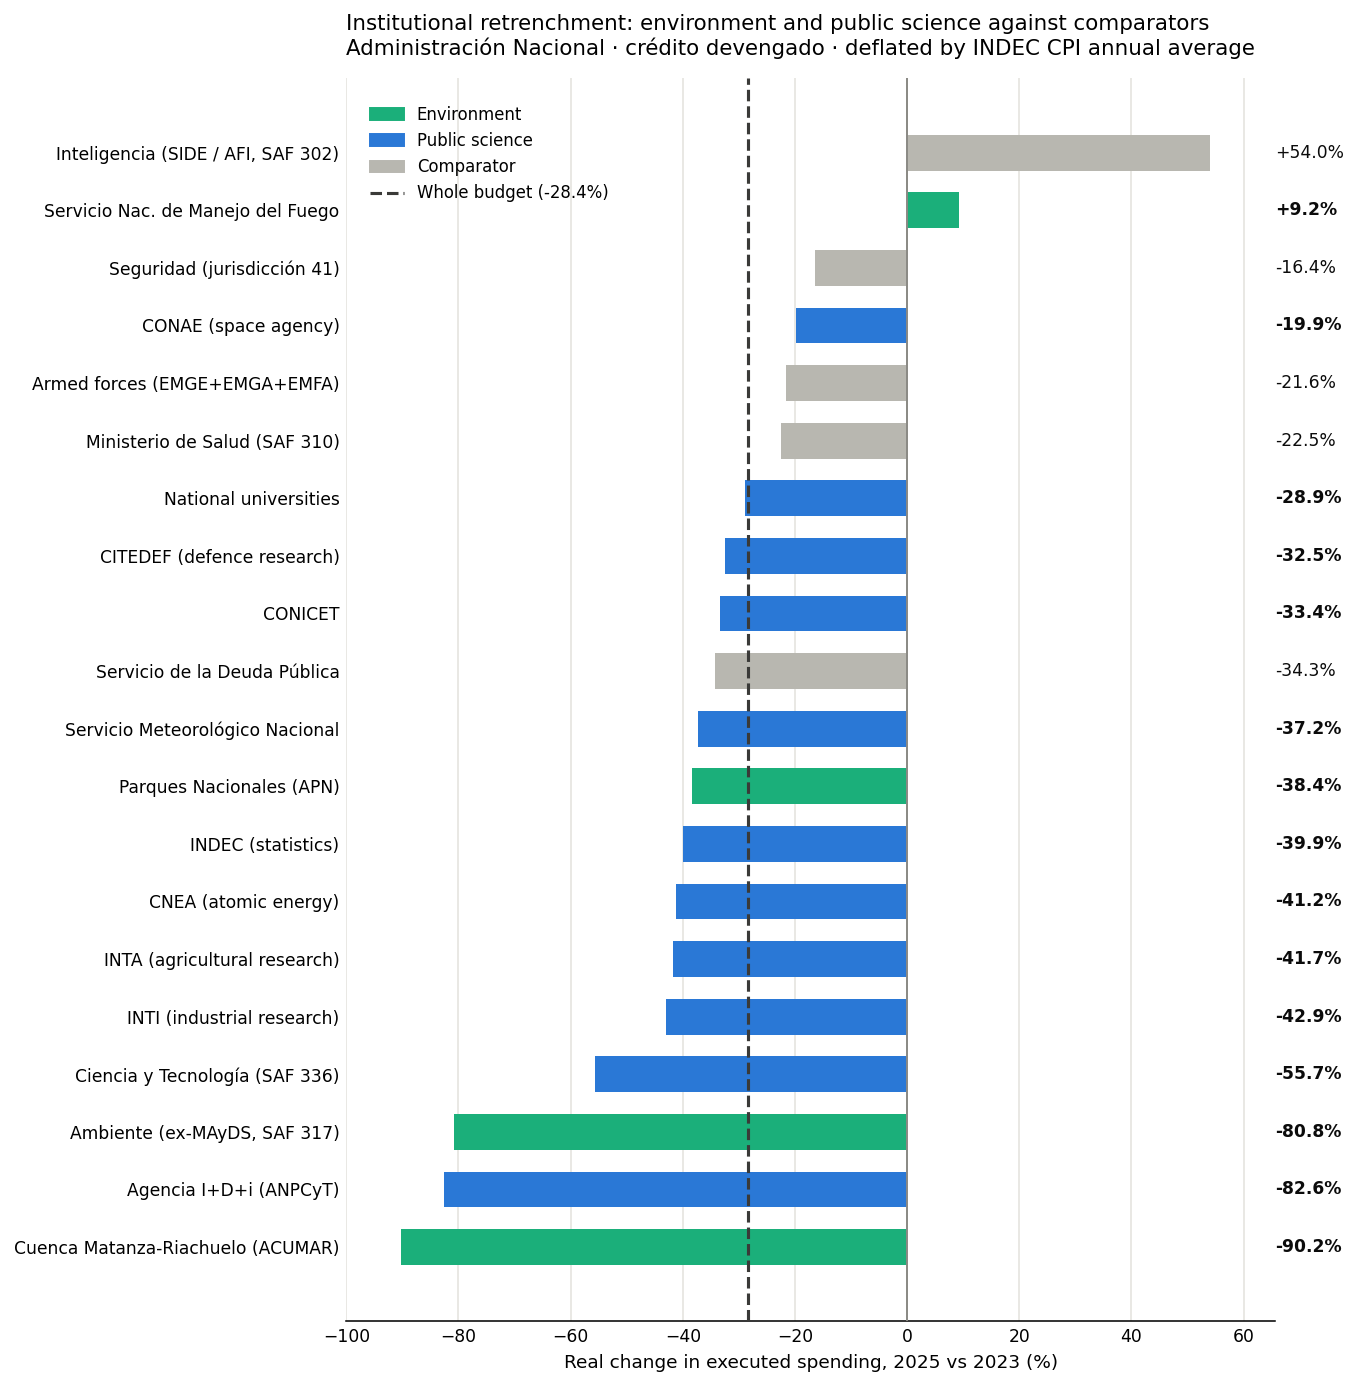

In [15]:
plot = res.reset_index()
plot = plot[plot["class"] != "Total"].sort_values("real_chg")
colors = {"Environment": "#1baf7a", "Public science": "#2a78d6", "Comparator": "#b8b7b0"}

lo = min(-100, plot.real_chg.min() * 100 - 6)
hi = max(60, plot.real_chg.max() * 100 + 6)
label_x = hi + (hi - lo) * 0.035          # fixed column for value labels, outside the plot area

fig, ax = plt.subplots(figsize=(9.8, 0.38 * len(plot) + 2.4), dpi=140)
ax.barh(plot.group, plot.real_chg * 100,
        color=[colors[c] for c in plot["class"]], height=0.62, zorder=3)
ax.axvline(0, color="#8a8984", lw=1, zorder=4)
ax.axvline(total_real * 100, color="#3a3a38", lw=1.6, ls="--", zorder=4)

# Value labels in a fixed right-hand column so they never collide with bars or the reference line.
for y_, (v, cls) in enumerate(zip(plot.real_chg * 100, plot["class"])):
    ax.text(label_x, y_, f"{v:+.1f}%", va="center", ha="left", fontsize=8.8,
            color="#0b0b0b", fontweight="bold" if cls in ("Environment", "Public science") else "normal")

ax.set_xlim(lo, label_x)
ax.set_xlabel("Real change in executed spending, 2025 vs 2023 (%)", fontsize=9.5)
ax.set_title("Institutional retrenchment: environment and public science against comparators\n"
             "Administración Nacional · crédito devengado · deflated by INDEC CPI annual average",
             fontsize=11, loc="left", pad=12)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
handles.append(plt.Line2D([0], [0], color="#3a3a38", lw=1.6, ls="--"))
ax.legend(handles, list(colors) + [f"Whole budget ({total_real:+.1%})"],
          fontsize=8.5, frameon=False, loc="upper left", bbox_to_anchor=(0.01, 0.99))
ax.grid(axis="x", color="#e3e2dd", zorder=0)
ax.set_axisbelow(True)
ax.set_xticks([t for t in range(int(lo // 20 * 20), int(hi) + 1, 20)])
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
ax.tick_params(labelsize=8.8, length=0)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig2_institutional_real_change.png", dpi=300, bbox_inches="tight")
plt.show()

---
## 8. Export

In [16]:
res.round(6).to_csv(OUT_DIR / "panel_institucional_indicadores.csv")
panel.to_csv(OUT_DIR / "panel_institucional_raw.csv", index=False)
comp.to_csv(OUT_DIR / "concordancia_jurisdicciones_2023_2025.csv")
side[["saf_2023", "jur_2023", "saf_2025", "jur_2025"]].to_csv(OUT_DIR / "concordancia_saf_focal.csv")
print("written to", OUT_DIR.resolve())

written to /home/claude/d2/outputs


---
## 9. Sources

- **Presupuesto Abierto** (DGSIAF, Secretaría de Hacienda, Ministerio de Economía).
  *Presupuesto de gastos y su ejecución detallada — agrupación anual*, 2023 and 2025 files.
  <https://www.presupuestoabierto.gob.ar/sici/datos-abiertos> · CC-BY 4.0.
  Field documentation: <https://dgsiaf-repo.mecon.gob.ar/repository/pa/credito-anual.pdf>
- **INDEC.** Índice de Precios al Consumidor, nivel general, nacional, base dic-2016 = 100.
  Series `148.3_INIVELNAL_DICI_M_26` via <https://apis.datos.gob.ar/series/api/>.
- **MCPSPN 2026.** *Manual de Clasificaciones Presupuestarias para el Sector Público Nacional*,
  7th ed., Oficina Nacional de Presupuesto. <https://www.economia.gob.ar/onp/sistema/> —
  normative definition of every classifier used here.
- **Cena Trebucq, M. (2026).** *Presupuesto ambiental en Argentina: la consolidación de un
  ajuste.* Buenos Aires: FARN. Used as an external validation benchmark (Sections 3 and 5.1),
  not as a data source.